# Expérience — Prédiction du prix avec XGBoost

Les expériences [01](01_rag_filtre.ipynb) et [02](02_rag_filtre_v2.ipynb) estimaient le prix d'une maison en demandant à un LLM d'ajuster le prix de ventes comparables. Ce notebook teste une approche classique d'apprentissage supervisé : un modèle de **gradient boosting sur arbres de décision**, XGBoost, entraîné directement sur les 79 caractéristiques de `train.csv`.

Pour que la comparaison soit directe, nous reprenons **la même partition** (80 % / 20 %, graine 42), donc les mêmes 292 maisons de validation, et **la même métrique** : la RMSE des logarithmes.

### Résultats des expériences RAG (maisons de validation)

| Méthode | RMSE des logarithmes |
|---|---|
| Médiane des comparables, RAG filtré v2 | 0,192 |
| LLM + RAG filtré v1 | 0,140 |
| LLM + RAG filtré v2 | 0,133 |

Les prédictions du LLM (v1 et v2) sont relues dans leurs caches à la section 5 et comparées à XGBoost sur les mêmes maisons.

### Pourquoi XGBoost?

L'analyse exploratoire ([étape 3](../03_analyse_exploratoire.ipynb)) a relevé plusieurs défis que les arbres de décision gèrent bien :

- **Relations non linéaires et seuils** (prix stable avant 1980, accélération avec `OverallQual`) : les arbres découpent les variables en intervalles.
- **Variables asymétriques et valeurs extrêmes** dans les caractéristiques : un arbre ne dépend que de l'ordre des valeurs, aucune transformation `log1p` n'est nécessaire.
- **Valeurs manquantes inconnues** (`LotFrontage`, 17,7 %) : XGBoost apprend pour chaque division la direction à donner aux valeurs absentes; aucune imputation n'est nécessaire.
- **Variables corrélées** : la redondance gêne peu la prédiction (elle complique seulement l'interprétation des importances).

Les **variables catégorielles** doivent par contre être converties en nombres. Nous utilisons un **encodage *one-hot*** : une colonne binaire par modalité.

## 1. Configuration

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    KFold, RandomizedSearchCV, cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

# Repérer la racine depuis le dossier courant ou l'un de ses parents.
current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "pyproject.toml").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt MAP6014.")
data_dir = root / "data"

# Partition (identique aux expériences RAG)
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

# Validation croisée sur l'entraînement
N_FOLDS = 5
RUN_SEARCH = True    # False : sauter la recherche aléatoire (environ 3 minutes)
N_ITER = 25          # configurations testées par la recherche aléatoire

# Encodage one-hot : modalités vues moins de MIN_CATEGORY_COUNT fois regroupées
MIN_CATEGORY_COUNT = 5

# Soumission Kaggle (fichier ignoré par Git)
MAKE_SUBMISSION = True
submission_path = root / "submissions" / "03_xgboost.csv"

# Prédictions des expériences RAG (lecture seule)
rag_caches = {
    "LLM + RAG filtré (v1)": data_dir / "cache_rag" / "llm_predictions.jsonl",
    "LLM + RAG filtré (v2)": data_dir / "cache_rag" / "llm_predictions_v2.jsonl",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
print(f"XGBoost {xgboost.__version__}")


def format_dollars(value):
    """Afficher un montant en dollars avec une espace comme séparateur de milliers."""
    return f"{value:,.0f} $".replace(",", " ")

XGBoost 3.4.1


## 2. Partition entraînement / validation

La partition est celle des expériences RAG : mêmes paramètres de `train_test_split`, donc mêmes 1 168 maisons d'entraînement et mêmes 292 maisons de validation. **Tous les choix de ce notebook** (hyperparamètres, retrait des valeurs atypiques, choix du modèle final) **sont faits par validation croisée sur l'entraînement seulement**. La validation ne sert qu'une fois, à la fin, pour mesurer l'erreur des modèles retenus.

In [2]:
read_options = {"na_values": ["NA"], "keep_default_na": False}
train_full = pd.read_csv(data_dir / "train.csv", **read_options)
test = pd.read_csv(data_dir / "test.csv", **read_options)
assert train_full.shape == (1460, 81) and test.shape == (1459, 80)

train_part, valid_part = train_test_split(
    train_full, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE
)
train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)
assert not set(train_part["Id"]) & set(valid_part["Id"])

# Cible : logarithme du prix, l'échelle de la métrique Kaggle.
y_train = np.log(train_part["SalePrice"])
y_valid = np.log(valid_part["SalePrice"])

display(pd.DataFrame({
    "Partition": ["Entraînement", "Validation", "test.csv (soumission)"],
    "Maisons": [len(train_part), len(valid_part), len(test)],
    "Prix médian": [format_dollars(train_part["SalePrice"].median()),
                    format_dollars(valid_part["SalePrice"].median()), "inconnu"],
}))

,Partition,Maisons,Prix médian
0,Entraînement,1168,165 000 $
1,Validation,292,154 150 $
2,test.csv (soumission),1459,inconnu


## 3. Prétraitement

### 3.1 Corrections et variables calculées

La fonction `prepare_features` applique les pistes de la synthèse de l'étape 3. Elle traite chaque maison **indépendamment des autres** : elle n'apprend aucune statistique des données et peut donc être appliquée avant la partition sans fuite d'information.

| Constat de l'étape 3 | Traitement |
|---|---|
| `NA` signifie l'absence d'un équipement pour 14 variables | Remplacé par la catégorie `Aucun` |
| `MSSubClass` est un code nominal enregistré avec des nombres | Converti en texte, donc encodé en *one-hot* |
| `GarageYrBlt` = 2207, postérieure à la vente | Remplacé par une valeur absente |
| Codes de `Exterior2nd` différents de ceux de `Exterior1st` | Harmonisés (`Wd Shng` → `WdShing`, `CmentBd` → `CemntBd`, `Brk Cmn` → `BrkComm`) |
| Années difficiles à interpréter directement | Âge à la vente et années depuis la rénovation |
| Surfaces fortement corrélées | Surface totale `GrLivArea + TotalBsmtSF` et nombre total de salles de bain |

Les autres valeurs absentes (`LotFrontage`, `MasVnrArea`, quelques valeurs de `test.csv`) sont **laissées absentes** : XGBoost les gère nativement.

In [3]:
ABSENCE_COLUMNS = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]
EXTERIOR2_FIXES = {"Wd Shng": "WdShing", "CmentBd": "CemntBd", "Brk Cmn": "BrkComm"}


def prepare_features(frame):
    """Corrections et variables calculées, maison par maison (aucun apprentissage)."""
    X = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    X["MSSubClass"] = X["MSSubClass"].astype(str)
    X[ABSENCE_COLUMNS] = X[ABSENCE_COLUMNS].fillna("Aucun")
    X.loc[X["GarageYrBlt"].gt(X["YrSold"]), "GarageYrBlt"] = np.nan
    X["Exterior2nd"] = X["Exterior2nd"].replace(EXTERIOR2_FIXES)

    X["TotalSF"] = X["GrLivArea"] + X["TotalBsmtSF"].fillna(0)
    X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    X["YearsSinceRemod"] = X["YrSold"] - X["YearRemodAdd"]
    X["TotalBath"] = (
        X["FullBath"] + 0.5 * X["HalfBath"]
        + X["BsmtFullBath"].fillna(0) + 0.5 * X["BsmtHalfBath"].fillna(0)
    )
    return X


X_train = prepare_features(train_part)
X_valid = prepare_features(valid_part)
X_test = prepare_features(test)

categorical_columns = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_columns = [c for c in X_train.columns if c not in categorical_columns]
print(f"{len(categorical_columns)} variables catégorielles, {len(numeric_columns)} numériques "
      f"(dont 4 calculées).")
print(f"Valeurs absentes restantes dans l'entraînement : "
      f"{X_train[numeric_columns].isna().sum().loc[lambda s: s > 0].to_dict()}")

44 variables catégorielles, 39 numériques (dont 4 calculées).
Valeurs absentes restantes dans l'entraînement : {'LotFrontage': 217, 'MasVnrArea': 6, 'GarageYrBlt': 64}


### 3.2 Encodage *one-hot*

`OneHotEncoder` crée une colonne binaire par modalité d'une variable catégorielle. Deux options répondent aux constats de l'étape 3 :

- `min_frequency=5` regroupe les modalités vues **moins de cinq fois** dans l'entraînement en une seule colonne « rares ». Une modalité présente chez deux maisons ne permet pas d'apprendre un effet fiable et augmente le risque de surapprentissage.
- `handle_unknown="infrequent_if_exist"` envoie une modalité **inconnue** de l'entraînement (par exemple le code 150 de `MSSubClass`, présent seulement dans `test.csv`) dans cette même colonne « rares », au lieu de provoquer une erreur.

L'encodeur est placé dans un `Pipeline` avec le modèle : en validation croisée, les modalités et leurs fréquences sont apprises **sur les plis d'entraînement seulement**. Les colonnes numériques passent sans transformation.

Contrairement à un modèle linéaire, un arbre n'a pas besoin de retirer une colonne de référence (`drop="first"`) : la colinéarité parfaite entre les colonnes d'une même variable ne pose pas de problème numérique.

In [4]:
def make_encoder():
    return ColumnTransformer(
        [("onehot",
          OneHotEncoder(handle_unknown="infrequent_if_exist",
                        min_frequency=MIN_CATEGORY_COUNT, sparse_output=False),
          categorical_columns)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )


def make_model(**xgb_params):
    params = {"random_state": RANDOM_STATE, "n_jobs": -1, "tree_method": "hist"}
    params.update(xgb_params)
    return Pipeline([("encoder", make_encoder()), ("xgb", XGBRegressor(**params))])


encoder_preview = make_encoder().fit(X_train)
encoded_names = encoder_preview.get_feature_names_out()
onehot = encoder_preview.named_transformers_["onehot"]
n_onehot = len(encoded_names) - len(numeric_columns)
n_categories = sum(len(categories) for categories in onehot.categories_)
n_grouped = sum(
    len(rare) for rare in onehot.infrequent_categories_ if rare is not None
)
print(f"{len(categorical_columns)} variables catégorielles → {n_onehot} colonnes binaires "
      f"({n_categories} modalités observées, dont {n_grouped} regroupées comme rares).")
print(f"Matrice finale : {len(X_train)} maisons × {len(encoded_names)} colonnes.")
print("Exemple, Neighborhood :",
      [name for name in encoded_names if name.startswith("Neighborhood_")][:6], "...")

44 variables catégorielles → 250 colonnes binaires (281 modalités observées, dont 56 regroupées comme rares).
Matrice finale : 1168 maisons × 289 colonnes.
Exemple, Neighborhood : ['Neighborhood_Blmngtn', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor'] ...


## 4. Choix du modèle par validation croisée

Nous comparons trois configurations par **validation croisée à 5 plis** sur les 1 168 maisons d'entraînement. Le modèle prédit `log(SalePrice)`; la RMSE calculée par `cross_val_score` est donc directement la RMSE des logarithmes.

1. **XGBoost par défaut** : paramètres de la bibliothèque (100 arbres, profondeur 6, taux d'apprentissage 0,3). C'est la référence.
2. **Configuration manuelle** : paramètres usuels pour un petit jeu tabulaire. Un taux d'apprentissage faible (0,02) avec beaucoup d'arbres (2 000) corrige l'erreur par petits pas; des arbres peu profonds (4) et l'échantillonnage des maisons (`subsample`) et des colonnes (`colsample_bytree`) limitent le surapprentissage.
3. **Recherche aléatoire** : 25 combinaisons tirées autour de la configuration manuelle (profondeur, poids minimal des feuilles, échantillonnage et régularisations L1, L2 et `gamma`).

In [5]:
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

MANUAL_PARAMS = {
    "n_estimators": 2000, "learning_rate": 0.02, "max_depth": 4, "min_child_weight": 2,
    "subsample": 0.7, "colsample_bytree": 0.5, "reg_lambda": 1.0,
}

candidates = {
    "XGBoost par défaut": make_model(),
    "XGBoost manuel": make_model(**MANUAL_PARAMS),
}

cv_rows = {}
for name, model in candidates.items():
    start = time.perf_counter()
    scores = -cross_val_score(model, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error")
    cv_rows[name] = {"RMSE log (moyenne)": scores.mean(), "Écart type entre plis": scores.std(),
                     "Durée (s)": time.perf_counter() - start}
display(pd.DataFrame(cv_rows).T.style.format("{:.4f}", subset=["RMSE log (moyenne)",
                                                               "Écart type entre plis"])
        .format("{:.1f}", subset=["Durée (s)"]))

,RMSE log (moyenne),Écart type entre plis,Durée (s)
XGBoost par défaut,0.1377,0.0143,1.4
XGBoost manuel,0.1195,0.0157,7.7


### Recherche aléatoire des hyperparamètres

`RandomizedSearchCV` tire `N_ITER` combinaisons dans les distributions ci-dessous et évalue chacune avec les mêmes 5 plis. Le nombre d'arbres et le taux d'apprentissage restent ceux de la configuration manuelle. Les régularisations sont tirées sur une échelle logarithmique, car leur effet varie selon l'ordre de grandeur.

In [6]:
search_space = {
    "xgb__max_depth": randint(2, 7),
    "xgb__min_child_weight": randint(1, 8),
    "xgb__subsample": uniform(0.5, 0.5),           # entre 0,5 et 1
    "xgb__colsample_bytree": uniform(0.2, 0.6),    # entre 0,2 et 0,8
    "xgb__reg_lambda": loguniform(0.1, 10),
    "xgb__reg_alpha": loguniform(1e-4, 1),
    "xgb__gamma": loguniform(1e-4, 0.1),
}

if RUN_SEARCH:
    start = time.perf_counter()
    search = RandomizedSearchCV(
        make_model(**MANUAL_PARAMS), search_space, n_iter=N_ITER, cv=cv,
        scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1,
    )
    search.fit(X_train, y_train)
    best_index = search.best_index_
    cv_rows["XGBoost recherche aléatoire"] = {
        "RMSE log (moyenne)": -search.best_score_,
        "Écart type entre plis": search.cv_results_["std_test_score"][best_index],
        "Durée (s)": time.perf_counter() - start,
    }
    candidates["XGBoost recherche aléatoire"] = make_model(**MANUAL_PARAMS).set_params(
        **search.best_params_
    )

    top = (pd.DataFrame(search.cv_results_)
           .sort_values("rank_test_score").head(5)
           .assign(**{"RMSE log": lambda f: -f["mean_test_score"]}))
    param_columns = [f"param_{name}" for name in search_space]
    display(top[["RMSE log", "std_test_score", *param_columns]]
            .rename(columns=lambda c: c.replace("param_xgb__", ""))
            .round(4).reset_index(drop=True))

cv_summary = pd.DataFrame(cv_rows).T.sort_values("RMSE log (moyenne)")
display(cv_summary.style.format("{:.4f}", subset=["RMSE log (moyenne)", "Écart type entre plis"])
        .format("{:.1f}", subset=["Durée (s)"]))

,RMSE log,std_test_score,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma
0,0.1189,0.0158,4,2,0.6616,0.4504,7.6881,0.0022,0.0005
1,0.1193,0.0146,3,1,0.6626,0.7179,0.4188,0.0002,0.0074
2,0.1196,0.0134,4,1,0.7197,0.6565,0.1666,0.0696,0.0048
3,0.1196,0.0169,2,1,0.9077,0.2992,0.1026,0.0006,0.0001
4,0.1201,0.0155,2,3,0.7252,0.3198,2.2941,0.2753,0.0035


,RMSE log (moyenne),Écart type entre plis,Durée (s)
XGBoost recherche aléatoire,0.1189,0.0158,183.3
XGBoost manuel,0.1195,0.0157,7.7
XGBoost par défaut,0.1377,0.0143,1.4


**Interprétation.** Lors de notre exécution, la configuration par défaut obtient une RMSE des logarithmes de 0,138 en validation croisée. La configuration manuelle descend à **0,1195**, une baisse de 13 % : avec un taux d'apprentissage de 0,3, les 100 arbres profonds par défaut s'ajustent trop vite à l'entraînement. La recherche aléatoire trouve **0,1189**, un gain de 0,0006 seulement, très inférieur à l'écart type entre plis (environ 0,016). Les cinq meilleures combinaisons sont à moins de 0,0012 les unes des autres, avec des paramètres très différents (profondeur de 2 à 4, `colsample_bytree` de 0,30 à 0,72) : dans cette région, la performance dépend peu des hyperparamètres.

**Conséquence.** Selon la règle fixée d'avance, le modèle retenu est celui de la recherche aléatoire, mais il n'est pas réellement meilleur que la configuration manuelle, qui coûte 18 fois moins de temps de calcul (9 s contre environ 160 s).

### Retrait des deux ventes atypiques

L'étape 3 a repéré deux ventes très atypiques (Id 524 et 1299 : plus de 4 500 pi² habitables, vendues moins de 185 000 \$). Elles pourraient tirer le modèle vers de mauvaises prédictions pour les très grandes maisons. Nous vérifions par validation croisée si les retirer **de l'entraînement** améliore les prédictions. Elles restent dans les plis d'évaluation : retirer des maisons difficiles de l'évaluation améliorerait le score artificiellement.

In [7]:
best_name = cv_summary.index[0]
atypical = (train_part["GrLivArea"].gt(4000) & train_part["SalePrice"].lt(300_000)).to_numpy()
print(f"Configuration testée : {best_name}")
print(f"Ventes atypiques dans l'entraînement : "
      f"{train_part.loc[atypical, 'Id'].tolist()}")

fold_scores = {"Avec les ventes atypiques": [], "Sans les ventes atypiques": []}
for fit_index, eval_index in cv.split(X_train):
    for label, keep in [("Avec les ventes atypiques", np.ones(len(fit_index), dtype=bool)),
                        ("Sans les ventes atypiques", ~atypical[fit_index])]:
        model = candidates[best_name]
        model.fit(X_train.iloc[fit_index[keep]], y_train.iloc[fit_index[keep]])
        error = model.predict(X_train.iloc[eval_index]) - y_train.iloc[eval_index]
        fold_scores[label].append(np.sqrt(np.mean(error ** 2)))

outlier_summary = pd.DataFrame(fold_scores, index=[f"Pli {i + 1}" for i in range(N_FOLDS)]).T
outlier_summary["Moyenne"] = outlier_summary.mean(axis=1)
display(outlier_summary.round(4))
DROP_ATYPICAL = bool(outlier_summary.loc["Sans les ventes atypiques", "Moyenne"]
                     < outlier_summary.loc["Avec les ventes atypiques", "Moyenne"])
print(f"Retirer les ventes atypiques de l'entraînement : {DROP_ATYPICAL}")

Configuration testée : XGBoost recherche aléatoire
Ventes atypiques dans l'entraînement : [524, 1299]


,Pli 1,Pli 2,Pli 3,Pli 4,Pli 5,Moyenne
Avec les ventes atypiques,0.1289,0.1200,0.1421,0.0988,0.1044,0.1189
Sans les ventes atypiques,0.1282,0.1324,0.1520,0.1004,0.1022,0.1230


Retirer les ventes atypiques de l'entraînement : False


**Interprétation.** Retirer les maisons 524 et 1299 de l'entraînement fait passer la RMSE moyenne de 0,1189 à **0,1230**. L'effet varie selon les plis : léger gain aux plis 1 et 5, perte aux plis 2, 3 et 4. Contrairement à un modèle linéaire, qu'une seule valeur extrême peut faire pivoter, un arbre isole ces ventes dans quelques feuilles : leur influence reste locale. Les retirer prive aussi le modèle de deux des rares exemples de très grandes maisons.

**Conséquence.** Nous conservons toutes les ventes (`DROP_ATYPICAL = False`). Cette conclusion est propre à XGBoost : elle devra être vérifiée de nouveau pour un modèle linéaire.

## 5. Entraînement final et évaluation sur la validation

Chaque configuration est réentraînée sur les 1 168 maisons d'entraînement (sans les ventes atypiques si la validation croisée l'a recommandé), puis évaluée **une seule fois** sur les 292 maisons de validation. Les prédictions sont ramenées en dollars par l'exponentielle.

Le **modèle retenu** est celui qui a la meilleure RMSE en validation croisée, choisi **avant** de regarder la validation. Les autres lignes du tableau sont données à titre de comparaison.

In [8]:
def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "RMSE log": np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2)),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
        "Maisons": len(y_true),
    }


fit_mask = ~atypical if DROP_ATYPICAL else np.ones(len(X_train), dtype=bool)
predictions = pd.DataFrame({
    "Id": valid_part["Id"],
    "SalePrice": valid_part["SalePrice"],
    "Médiane globale": train_part["SalePrice"].median(),
})
fitted = {}
for name, model in candidates.items():
    model.fit(X_train[fit_mask], y_train[fit_mask])
    fitted[name] = model
    predictions[name] = np.exp(model.predict(X_valid))

final_name = best_name
final_model = fitted[final_name]
print(f"Modèle retenu (meilleure validation croisée) : {final_name}")

Modèle retenu (meilleure validation croisée) : XGBoost recherche aléatoire


### Comparaison avec les expériences RAG

Les prédictions du LLM sont relues dans les caches des expériences 01 et 02, sans nouvel appel. La comparaison porte sur les maisons prédites par toutes les méthodes (le cache de la version 1 contient une maison de moins).

In [9]:
for label, path in rag_caches.items():
    if path.exists():
        cached = (pd.read_json(path, lines=True).query("with_rag")
                  .drop_duplicates("Id", keep="last").set_index("Id")["predicted_price"])
        predictions[label] = predictions["Id"].map(cached)
    else:
        print(f"Cache absent, méthode ignorée : {path.name}")

methods = [c for c in predictions.columns if c not in {"Id", "SalePrice"}]
common = predictions.dropna(subset=methods)

results = pd.DataFrame(
    {method: regression_metrics(common["SalePrice"], common[method]) for method in methods}
).T.sort_values("RMSE log")
results.insert(0, "RMSE log (validation croisée)", cv_summary["RMSE log (moyenne)"])
display(results.style.format({
    "RMSE log (validation croisée)": "{:.4f}", "RMSE log": "{:.4f}", "RMSE ($)": "{:,.0f}",
    "MAE ($)": "{:,.0f}", "R²": "{:.3f}", "Maisons": "{:.0f}",
}, na_rep="—"))

,RMSE log (validation croisée),RMSE log,RMSE ($),MAE ($),R²,Maisons
XGBoost manuel,0.1195,0.1253,"25,278","14,475",0.917,291
XGBoost recherche aléatoire,0.1189,0.1296,"26,707","15,063",0.907,291
LLM + RAG filtré (v2),—,0.1329,"25,917","16,513",0.913,291
LLM + RAG filtré (v1),—,0.1399,"27,801","18,168",0.900,291
XGBoost par défaut,0.1377,0.1473,"26,527","16,889",0.909,291
Médiane globale,—,0.4330,"88,814","59,718",-0.025,291


**Interprétation.** Sur les 291 maisons communes, les deux configurations réglées de XGBoost font mieux que les deux versions du LLM : **0,1253** pour la configuration manuelle et **0,1296** pour le modèle retenu, contre 0,1329 pour le LLM v2 et 0,1399 pour le LLM v1. La MAE suit le même ordre (14 475 \$ et 15 063 \$, contre 16 513 \$ pour le LLM v2). La RMSE en dollars, dominée par les maisons chères, est par contre semblable pour XGBoost et le LLM v2 : le LLM prédit mieux le haut du marché (voir la figure suivante).

Le modèle retenu fait un peu moins bien en validation que la configuration manuelle, alors qu'il était légèrement meilleur en validation croisée. L'écart (0,004) est du même ordre que la variabilité entre plis et confirme que les deux configurations sont équivalentes. XGBoost par défaut (0,147) est moins bon que le LLM v2 : le réglage des hyperparamètres est nécessaire. Enfin, les RMSE de validation sont un peu plus élevées que celles de la validation croisée (0,130 contre 0,119), ce qui suggère que ces 292 maisons sont légèrement plus difficiles que la moyenne; les écarts entre méthodes, mesurés sur les mêmes maisons, restent comparables.

**Conséquence.** Un modèle entraîné en quelques secondes, sans coût d'API et de façon déterministe, atteint une erreur plus faible que le LLM avec RAG filtré. XGBoost devient notre référence pour l'étape de modélisation.

### Prédictions et prix réels

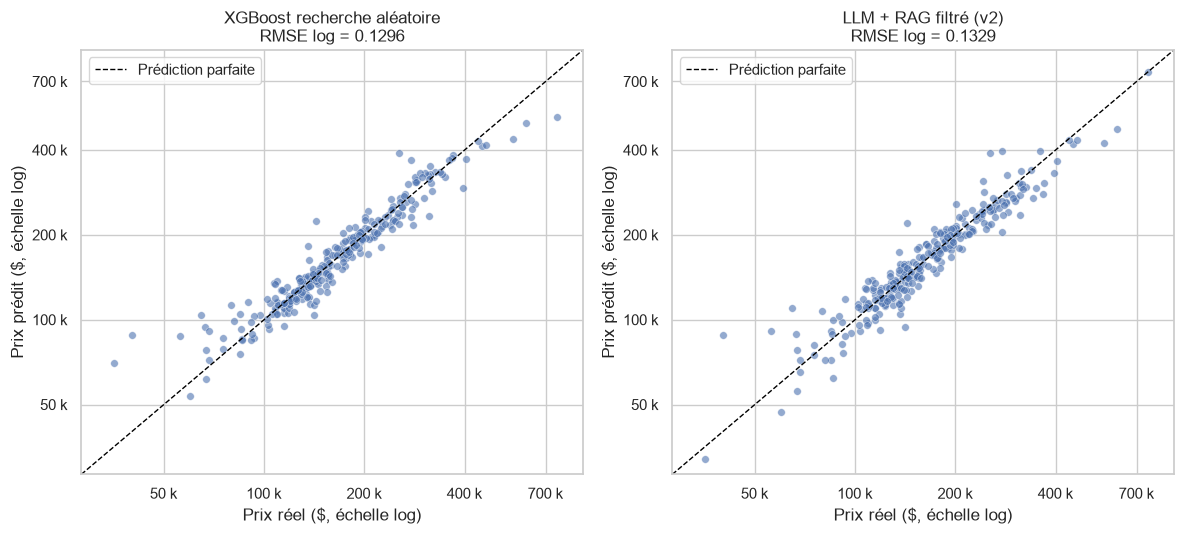

Corrélation des erreurs log entre XGBoost recherche aléatoire et LLM + RAG filtré (v2) : 0.70
Moyenne géométrique des deux prédictions : RMSE log = 0.1209 (indicatif : combinaison choisie après avoir vu la validation)


In [10]:
llm_columns = [c for c in rag_caches if c in common.columns]
panels = [final_name] + llm_columns[-1:]
ticks = [50_000, 100_000, 200_000, 400_000, 700_000]
tick_labels = [f"{tick // 1000} k" for tick in ticks]
limits = (common["SalePrice"].min() * 0.8, common["SalePrice"].max() * 1.2)

fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 5.5), squeeze=False)
for ax, method in zip(axes[0], panels):
    sns.scatterplot(x=common["SalePrice"], y=common[method], alpha=0.6, s=30, ax=ax)
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=1,
            label="Prédiction parfaite")
    ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits,
           xlabel="Prix réel ($, échelle log)", ylabel="Prix prédit ($, échelle log)")
    ax.set_xticks(ticks, tick_labels)
    ax.set_yticks(ticks, tick_labels)
    ax.minorticks_off()
    rmse_log = regression_metrics(common["SalePrice"], common[method])["RMSE log"]
    ax.set_title(f"{method}\nRMSE log = {rmse_log:.4f}")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Les deux méthodes se trompent-elles sur les mêmes maisons?
if llm_columns:
    log_errors = pd.DataFrame({
        method: np.log(common[method]) - np.log(common["SalePrice"])
        for method in [final_name, llm_columns[-1]]
    })
    print(f"Corrélation des erreurs log entre {final_name} et {llm_columns[-1]} : "
          f"{log_errors.corr().iloc[0, 1]:.2f}")
    blend = np.exp(np.log(common[[final_name, llm_columns[-1]]]).mean(axis=1))
    print(f"Moyenne géométrique des deux prédictions : RMSE log = "
          f"{regression_metrics(common['SalePrice'], blend)['RMSE log']:.4f} "
          f"(indicatif : combinaison choisie après avoir vu la validation)")

**Question.** Les prédictions de XGBoost suivent-elles les prix réels sur toute l'étendue des prix, et ses erreurs ressemblent-elles à celles du LLM?

**Observation.** Les deux nuages sont serrés autour de la diagonale entre 100 000 \$ et 400 000 \$. Aux extrémités, XGBoost **comprime** ses prédictions : il surestime presque toutes les maisons vendues moins de 70 000 \$ et sous-estime les plus chères (la maison 692, vendue 755 000 \$, est prédite à 523 000 \$). Le LLM suit mieux le haut du marché. La corrélation des erreurs logarithmiques entre les deux méthodes est de 0,70 : elles se trompent souvent sur les mêmes maisons, mais pas toujours.

**Interprétation.** La compression est un comportement connu des arbres : chaque feuille prédit une moyenne des maisons d'entraînement qui y tombent, et les extrémités comptent peu de maisons. La moyenne géométrique des deux prédictions obtient 0,1209, mieux que chacune séparément, car une partie de leurs erreurs se compensent.

**Conséquence.** Une combinaison des deux approches est une piste, mais ce chiffre est optimiste : la combinaison a été imaginée après avoir vu la validation. Il faudrait la valider sur d'autres maisons, par exemple par validation croisée, ce qui exigerait des appels au LLM pour l'entraînement.

## 6. Variables les plus utiles au modèle

XGBoost mesure l'importance d'une colonne par son **gain** : l'amélioration moyenne de la fonction de perte apportée par les divisions qui utilisent cette colonne. Avec l'encodage *one-hot*, une variable comme `Neighborhood` est répartie sur une vingtaine de colonnes binaires; nous additionnons donc les gains de ses colonnes pour obtenir l'importance de la **variable d'origine**.

Ces importances décrivent le fonctionnement du modèle, pas des effets causaux. Entre deux variables corrélées (`GarageCars` et `GarageArea`), le modèle peut utiliser l'une ou l'autre presque indifféremment.

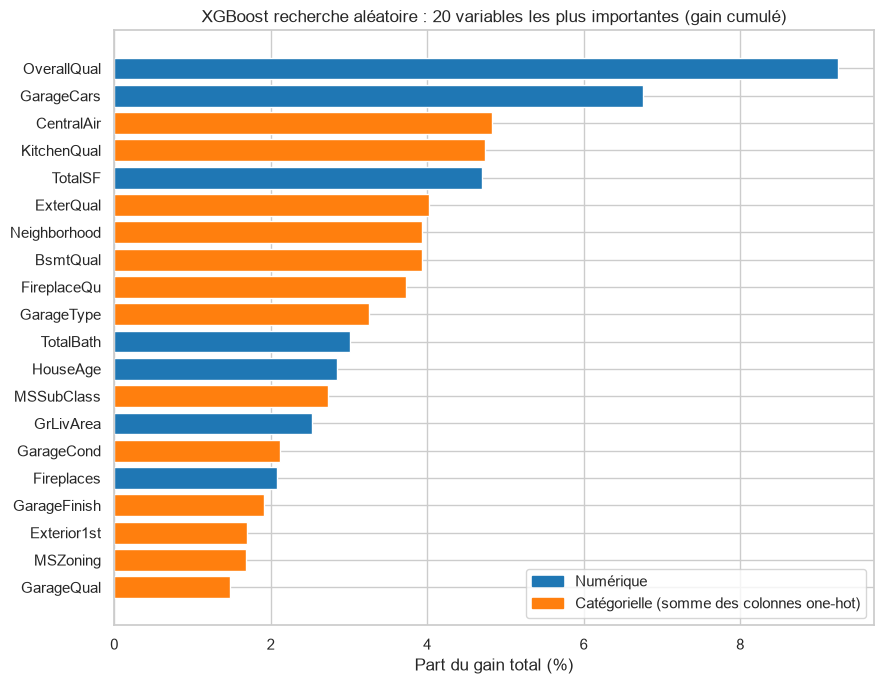

Colonnes one-hot les plus importantes :


,Part du gain (%)
ExterQual_TA,3.63
FireplaceQu_Aucun,3.19
KitchenQual_TA,3.05
BsmtQual_Ex,2.98
CentralAir_Y,2.73
CentralAir_N,2.11
KitchenQual_Ex,1.45
GarageFinish_Aucun,1.35


In [11]:
encoded_names = final_model.named_steps["encoder"].get_feature_names_out()
gain = pd.Series(final_model.named_steps["xgb"].feature_importances_, index=encoded_names)


def original_variable(encoded_name):
    """Retrouver la variable d'origine d'une colonne one-hot (préfixe le plus long)."""
    if encoded_name in numeric_columns:
        return encoded_name
    return max((c for c in categorical_columns if encoded_name.startswith(c + "_")), key=len)


by_variable = (gain.groupby(gain.index.map(original_variable)).sum()
               .sort_values(ascending=False))
by_variable = by_variable / by_variable.sum() * 100

fig, ax = plt.subplots(figsize=(9, 7))
top_variables = by_variable.head(20)
colors = ["tab:orange" if v in categorical_columns else "tab:blue" for v in top_variables.index]
ax.barh(top_variables.index[::-1], top_variables.values[::-1], color=colors[::-1])
ax.set_title(f"{final_name} : 20 variables les plus importantes (gain cumulé)")
ax.set_xlabel("Part du gain total (%)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:blue"),
                   plt.Rectangle((0, 0), 1, 1, color="tab:orange")],
          labels=["Numérique", "Catégorielle (somme des colonnes one-hot)"],
          loc="lower right")
plt.tight_layout()
plt.show()

print("Colonnes one-hot les plus importantes :")
display(gain[[n for n in gain.index if n not in numeric_columns]]
        .sort_values(ascending=False).head(8).div(gain.sum()).mul(100).round(2)
        .rename("Part du gain (%)").to_frame())

**Question.** Sur quelles variables le modèle s'appuie-t-il, et retrouve-t-on les constats de l'analyse exploratoire?

**Observation.** `OverallQual` arrive en tête (9 % du gain), suivie de `GarageCars` (7 %), conformément aux corrélations de l'étape 3. La surface totale calculée `TotalSF` (4,7 %) dépasse `GrLivArea` (2,5 %) : elle résume en une seule colonne deux surfaces fortement liées au prix. Les variables de qualité catégorielles (`KitchenQual`, `ExterQual`, `BsmtQual`, `FireplaceQu`) occupent une grande partie du classement, et leurs colonnes les plus utilisées sont `TA` (moyen) ou `Ex` (excellent). `CentralAir` est troisième et `Neighborhood` septième.

**Interprétation.** Le modèle sépare surtout les maisons de qualité « moyenne » des autres, ce qui confirme que ces variables suivent un ordre. Un encodage ordinal (`Po` < `Fa` < `TA` < `Gd` < `Ex`) permettrait le même découpage avec une seule colonne. L'absence de climatisation centrale caractérise les maisons anciennes et bon marché; c'est l'information qui manquait au LLM v1 pour les maisons 31 et 813. Pour une variable binaire comme `CentralAir`, les colonnes `CentralAir_Y` et `CentralAir_N` sont redondantes et se partagent le gain.

**Conséquence.** Ces constats orientent les pistes de la section 9 : encodage ordinal des qualités et variables combinées comme `TotalSF`.

## 7. Plus grandes erreurs

Le tableau présente les dix maisons de validation dont l'erreur de XGBoost est la plus grande, avec l'écart du LLM v2 sur les mêmes maisons lorsqu'il est disponible.

In [12]:
worst = common.assign(
    **{"Erreur absolue log": (np.log(common[final_name]) - np.log(common["SalePrice"])).abs(),
       "Écart XGBoost": common[final_name] / common["SalePrice"] - 1}
)
display_columns = ["Id", "SalePrice", final_name, "Écart XGBoost"]
formats = {"SalePrice": "{:,.0f}", final_name: "{:,.0f}", "Écart XGBoost": "{:+.0%}"}
if llm_columns:
    worst["Écart LLM"] = worst[llm_columns[-1]] / worst["SalePrice"] - 1
    display_columns.append("Écart LLM")
    formats["Écart LLM"] = "{:+.0%}"
worst = (worst.sort_values("Erreur absolue log", ascending=False).head(10)
         .merge(valid_part[["Id", "Neighborhood", "MSZoning", "SaleCondition", "GrLivArea",
                            "OverallQual", "OverallCond", "YearBuilt"]], on="Id"))
display(worst[display_columns + ["Neighborhood", "MSZoning", "SaleCondition", "GrLivArea",
                                 "OverallQual", "OverallCond", "YearBuilt"]]
        .style.format(formats).hide(axis="index"))

Id,SalePrice,XGBoost recherche aléatoire,Écart XGBoost,Écart LLM,Neighborhood,MSZoning,SaleCondition,GrLivArea,OverallQual,OverallCond,YearBuilt
31,"40,000","88,406",+121%,+120%,IDOTRR,C (all),Normal,1317,4,4,1920
917,"35,311","69,960",+98%,-9%,IDOTRR,C (all),Abnorml,480,2,3,1949
1433,"64,500","103,617",+61%,+71%,OldTown,RL,Normal,968,4,6,1927
813,"55,993","87,846",+57%,+63%,IDOTRR,C (all),Alloca,1044,5,5,1952
589,"143,000","223,549",+56%,+54%,ClearCr,RL,Partial,1473,5,8,1968
582,"253,293","390,073",+54%,+54%,NridgHt,RL,Partial,2042,8,5,2008
692,"755,000","522,753",-31%,+0%,NoRidge,RL,Normal,4316,10,6,1994
875,"66,500","94,308",+42%,+34%,OldTown,RM,Abnorml,1131,5,6,1941
590,"79,500","112,679",+42%,+35%,BrkSide,RM,Normal,935,5,6,1930
278,"141,000","103,582",-27%,-33%,Gilbert,RL,Normal,864,4,5,1951


**Interprétation.** Six des dix plus grandes erreurs sont des maisons vendues moins de 80 000 \$, toutes **surestimées**. Trois des quatre premières (31, 917 et 813) sont dans le quartier `IDOTRR`, en zonage commercial (`C (all)`); les maisons 31 et 813 étaient déjà les plus grandes erreurs du LLM v1. Ce zonage ne compte qu'une dizaine de ventes dans `train.csv` : trop peu pour que le modèle en apprenne l'effet. Deux ventes `Partial` (maisons neuves ou en construction, 589 et 582) sont surestimées d'environ 55 % par les deux méthodes.

Pour huit maisons sur dix, l'écart du LLM v2 est presque le même que celui de XGBoost : ces prix semblent difficiles à expliquer avec les variables disponibles (état réel non décrit, vente particulière). Les deux exceptions sont la maison 917, où le LLM n'a que −9 % d'écart, et la maison 692, que le LLM prédit **exactement** à 755 000 \$, le prix le plus élevé du jeu de données. Une prédiction exacte d'une valeur aussi extrême peut indiquer que le LLM a mémorisé cette vente publique; elle illustre le risque de contamination signalé dans les expériences RAG.

## 8. Soumission Kaggle

Pour la soumission, le modèle retenu est réentraîné avec les mêmes hyperparamètres sur **les 1 460 maisons de `train.csv`** (sans les ventes atypiques si la section 4 l'a recommandé), puis prédit les 1 459 maisons de `test.csv`. Le fichier est écrit dans `submissions/`, ignoré par Git, dans l'ordre de `sample_submission.csv`.

In [13]:
if MAKE_SUBMISSION:
    X_full = prepare_features(train_full)
    y_full = np.log(train_full["SalePrice"])
    keep_full = ~(train_full["GrLivArea"].gt(4000) & train_full["SalePrice"].lt(300_000))
    if not DROP_ATYPICAL:
        keep_full[:] = True

    submission_model = clone(final_model)  # mêmes hyperparamètres, non entraîné
    submission_model.fit(X_full[keep_full], y_full[keep_full])

    sample = pd.read_csv(data_dir / "sample_submission.csv")
    submission = pd.DataFrame({"Id": test["Id"],
                               "SalePrice": np.exp(submission_model.predict(X_test))})
    submission = sample[["Id"]].merge(submission, on="Id", how="left")
    assert len(submission) == len(test) and submission["SalePrice"].notna().all()

    submission_path.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(submission_path, index=False)
    print(f"Soumission écrite : {submission_path.relative_to(root)} "
          f"({len(submission)} maisons, entraînement sur {keep_full.sum()} ventes)")
    print(f"Prix médian prédit : {format_dollars(submission['SalePrice'].median())}")

Soumission écrite : submissions\03_xgboost.csv (1459 maisons, entraînement sur 1460 ventes)
Prix médian prédit : 156 767 $


## 9. Limites et pistes

- **Prédictions comprimées aux extrémités.** Les maisons très bon marché sont surestimées et les plus chères sous-estimées. Des variables plus fines pour ces segments (zonage commercial, état de la maison) ou une combinaison avec une autre méthode pourraient réduire ces erreurs.
- **Une seule partition de validation.** Avec 292 maisons, un écart de quelques millièmes de RMSE entre deux méthodes peut venir du hasard. La validation croisée sur l'entraînement donne une estimation plus stable pour comparer les configurations XGBoost entre elles.
- **Recherche d'hyperparamètres limitée.** 25 combinaisons avec un nombre d'arbres fixe. Un arrêt précoce (*early stopping*) sur un pli interne ou une recherche bayésienne pourraient affiner le réglage.
- **Encodage *one-hot* des variables ordinales.** Les qualités (`ExterQual`, `KitchenQual`, `BsmtQual`…) suivent un ordre (`Po` < `Fa` < `TA` < `Gd` < `Ex`) que le *one-hot* ignore. Un encodage ordinal permettrait à un seul découpage de séparer « bon ou mieux » de « moyen ou moins ». Piste à comparer en validation croisée.
- **Importances non causales.** Le gain dépend des corrélations entre variables et du hasard de l'échantillonnage des colonnes.
- **Comparaison avec le LLM.** Le LLM n'a jamais été entraîné sur notre partition, mais il a peut-être vu les données publiques d'Ames; XGBoost apprend uniquement des 1 168 maisons d'entraînement.